# code_002 · Specify the task and respect the information clock

**Book:** Chapter 1, section 1.1. **Purpose:** executable concept experiments, not a complete estimator hyperparameter course. All data and helper definitions are inside this notebook. Synthetic values are invented for teaching and provide no engineering validation.

Use the repository [quickstart](../README.md) and pinned environment. Restart the kernel and run all cells in order. Verified target: CPython 3.14.3 and scikit-learn 1.9.0, CPU only; no files, downloads, API keys or project imports are needed during execution. Allow a minute for execution plus time to reason through the prompts. Actual time, environment and checks are recorded at the end and in the [Chapter 1 execution report](../CHAPTER_01_EXECUTION.md).

Read each prediction prompt before running its experiment. Controls are identified as task, data-generation, model or decision controls; they are not interchangeable. The [stable directory](../CODE_EXAMPLES.md#code_002) links this example to the manuscript.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=101
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
assert sklearn.__version__=='1.9.0','Use the verified pinned environment.'
print(VERSIONS);print('CPU:',platform.system(),platform.machine())
plt.rcParams.update({'figure.dpi':100,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64


<a id="task-contract"></a>
## A task specification you can inspect

The stakeholder wants useful weekly inspections, not an abstract accuracy score. Our observation unit is a member-week; the action unit is a member inspection. We predict Monday at 08:00 whether an actionable finding will be recorded during the following seven days. That label is an inspection finding, not proven physical failure. We assume all members in this teaching cohort are inspected within the window so their labels are observed; selective inspection would make many outcomes unknown.

The worksheet is a dictionary with explicit information times, population and costs. Its validator can catch omissions, but it cannot decide whether a target is useful or whether a cost reflects stakeholder priorities. **Predict:** which field would you change if the inspection crew worked monthly instead of weekly? That is a task control, not a model hyperparameter.


In [2]:
spec={'population':'synthetic members with scheduled complete follow-up','observation_unit':'member-week',
'action_unit':'member inspection','prediction_time':'2026-10-05 08:00','horizon_days':7,
'target':'actionable finding during (prediction time, prediction time + 7 days]',
'allowed_inputs':['load_summary','age_years'],'miss_cost_units':100,'inspection_capacity':2}
required={'population','observation_unit','action_unit','prediction_time','horizon_days','target','allowed_inputs','miss_cost_units','inspection_capacity'}
assert required<=spec.keys() and spec['horizon_days']>0 and spec['inspection_capacity']>0
display(pd.DataFrame({'field':list(spec),'value':[str(v) for v in spec.values()]}))


,field,value
0,population,synthetic members with scheduled complete foll...
1,observation_unit,member-week
2,action_unit,member inspection
3,prediction_time,2026-10-05 08:00
4,horizon_days,7
5,target,"actionable finding during (prediction time, pr..."
6,allowed_inputs,"['load_summary', 'age_years']"
7,miss_cost_units,100
8,inspection_capacity,2


<a id="availability"></a>
## Event time is different from availability time

A measurement can describe yesterday yet arrive tomorrow. Features are usable only if both their event time and availability time respect the prediction cutoff and their meaning is legitimate. The deliberately unsafe feature list includes a delayed historical reading and an inspection result from the future label window. Filtering timestamps is necessary but not sufficient: a historical database may later overwrite an old record, and a field can encode the target through its semantics.

**Predict:** will checking event time alone catch both mistakes? Run the two policies and compare the feature names. The fixed cutoff is a task-design control; the delay is a data-availability condition.


,feature,event_time,available_time,event_only_ok,available_ok
0,load_summary,2026-10-04 12:00:00,2026-10-04 12:05:00,True,True
1,age_years,2026-10-01 00:00:00,2026-10-01 00:00:00,True,True
2,late_sensor_revision,2026-10-04 13:00:00,2026-10-06 00:00:00,True,False
3,future_inspection_grade,2026-10-08 00:00:00,2026-10-09 00:00:00,False,False


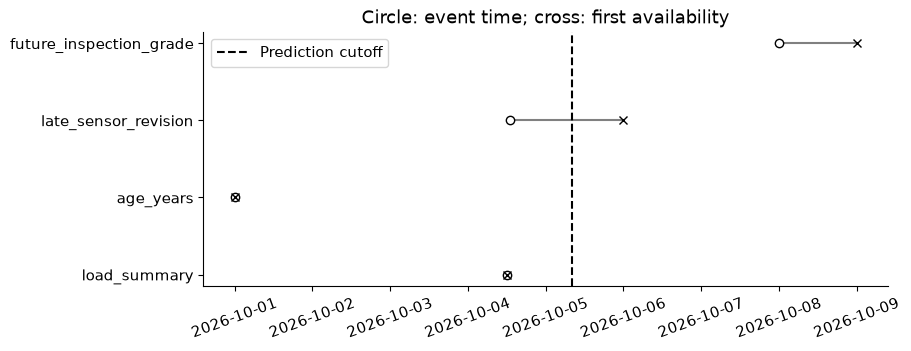

In [3]:
cutoff=pd.Timestamp(spec['prediction_time'])
features=pd.DataFrame({'feature':['load_summary','age_years','late_sensor_revision','future_inspection_grade'],
 'event_time':pd.to_datetime(['2026-10-04 12:00','2026-10-01','2026-10-04 13:00','2026-10-08'],format='ISO8601'),
 'available_time':pd.to_datetime(['2026-10-04 12:05','2026-10-01','2026-10-06','2026-10-09'],format='ISO8601')})
features['event_only_ok']=features.event_time<=cutoff
features['available_ok']=(features.event_time<=cutoff)&(features.available_time<=cutoff)
assert features.loc[features.feature=='late_sensor_revision','event_only_ok'].item()
assert not features.loc[features.feature=='late_sensor_revision','available_ok'].item()
assert set(features.loc[features.available_ok,'feature'])==set(spec['allowed_inputs'])
display(features)
fig,ax=plt.subplots(figsize=(9,3.4))
for i,row in features.iterrows():
 ax.plot([row.event_time,row.available_time],[i,i],color='.5')
 ax.plot(row.event_time,i,'o',mfc='white',mec='black');ax.plot(row.available_time,i,'x',color='black')
ax.axvline(cutoff,color='black',ls='--',label='Prediction cutoff')
ax.set_yticks(range(len(features)),features.feature);ax.set_title('Circle: event time; cross: first availability')
ax.tick_params(axis='x',rotation=20);ax.legend();plt.show()
RESULTS['unsafe_event_only_features']=features.loc[features.event_only_ok & ~features.available_ok,'feature'].tolist()


<a id="labels-units"></a>
## Units, horizons and complete follow-up

The same member can contribute several weeks, so different row IDs do not imply independent entities. We construct labels from event timestamps with an open left and closed right horizon. An event exactly at the prediction cutoff is not a future outcome; one exactly at the seven-day endpoint is included under this declared convention. A member with no event and incomplete follow-up must not silently become a negative label.

**Predict:** how many labels change if the horizon becomes three days? Inspect the member-week keys and the intentionally repeated members. Real data would need grouped/time-aware validation, outcome-availability checks and careful handling of action-dependent observation.


In [4]:
rows=pd.DataFrame({'member':['M1','M1','M2','M2'],
 'prediction_time':pd.to_datetime(['2026-10-05 08:00','2026-10-12 08:00']*2)})
events={'M1':pd.Timestamp('2026-10-08 08:00'),'M2':pd.Timestamp('2026-10-19 08:00')}
rows['event_time']=rows.member.map(events)
rows['followup_end']=pd.Timestamp('2026-10-20 08:00')
for h in [3,7]:
 end=rows.prediction_time+pd.Timedelta(days=h)
 complete=rows.followup_end>=end
 rows[f'label_{h}d']=np.where(complete,((rows.event_time>rows.prediction_time)&(rows.event_time<=end)).astype(int),np.nan)
assert not rows.duplicated(['member','prediction_time']).any()
assert rows.member.nunique()<len(rows)
assert rows.loc[0,'label_3d']==1 and rows.loc[3,'label_7d']==1
incomplete=rows.copy();incomplete['followup_end']=incomplete.prediction_time+pd.Timedelta(days=2)
assert (incomplete.followup_end<incomplete.prediction_time+pd.Timedelta(days=7)).all()
display(rows)
RESULTS['label_counts']={c:rows[c].value_counts().to_dict() for c in ['label_3d','label_7d']}


,member,prediction_time,event_time,followup_end,label_3d,label_7d
0,M1,2026-10-05 08:00:00,2026-10-08 08:00:00,2026-10-20 08:00:00,1.0,1.0
1,M1,2026-10-12 08:00:00,2026-10-08 08:00:00,2026-10-20 08:00:00,0.0,0.0
2,M2,2026-10-05 08:00:00,2026-10-19 08:00:00,2026-10-20 08:00:00,0.0,0.0
3,M2,2026-10-12 08:00:00,2026-10-19 08:00:00,2026-10-20 08:00:00,0.0,1.0


## Exercises and worksheet

1. Rewrite the specification for building-level monthly alarms. Explain what becomes one row, one action and one target.
2. Move the delayed reading's arrival before the cutoff; explain why the semantic audit is still necessary.
3. Remove complete follow-up for M2 and keep its label unknown rather than setting zero. What data would establish a negative?
4. Write two competing definitions of an actionable finding, then state who can resolve their disagreement.

**Optional hint:** labels describe a chosen observation process. A database check can enforce a timestamp convention but cannot prove that inspections reveal every physical fault. No fitted model is necessary to discover these framing defects.


## Interpretation, limits and next steps

The printed tables and figures are observations from this executed synthetic experiment. Describe the mechanism they demonstrate before comparing individual numbers. Fixed seeds make the teaching run reproducible; they do not establish performance in a new population. No deployment or physical validity guarantee follows from passing these checks. For model-specific controls, use the official documentation and the later model chapters; [code_001](../CODE_EXAMPLES.md#code_001) is a full decision-tree parameter laboratory.

**Troubleshooting:** a version assertion means the selected kernel differs from the pinned environment. Restart and run all cells rather than borrowing state from a different notebook. Missing or repeated timestamps require an explicit observation policy, not a silent row reorder. When adapting an experiment, record its new assumptions, selection rule and untouched assessment evidence. Initial package installation may use the internet; these cells do not.


In [5]:
EXECUTION_SUMMARY={'example_id':'code_002','versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU',
 'seed':SEED,'concepts_demonstrated':['task specification', 'observation versus action units', 'event versus availability time', 'future-information leakage', 'label horizon', 'follow-up and repeated entities'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:',json.dumps(EXECUTION_SUMMARY,sort_keys=True))


EXECUTION_SUMMARY_JSON: {"concepts_demonstrated": ["task specification", "observation versus action units", "event versus availability time", "future-information leakage", "label horizon", "follow-up and repeated entities"], "elapsed_seconds": 0.097, "example_id": "code_002", "hardware": "Darwin arm64 CPU", "results": {"label_counts": {"label_3d": {"0.0": 3, "1.0": 1}, "label_7d": {"0.0": 2, "1.0": 2}}, "unsafe_event_only_features": ["late_sensor_revision"]}, "seed": 101, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
